# Generation with base model (no custom oracle)


In [1]:
# Please run the following 'pip install' command to install the required libraries
!pip install jupyter ipywidgets loguru py3dmol rdkit pandas 2>/dev/null | tail -n 1

In [2]:
#install pubchemy
!pip install pubchempy 2>/dev/null | tail -n 1

In [3]:
# Importing libraries for 3-D visualization
#import py3Dmol
import ipywidgets as widgets
from IPython.display import display

# Importing libraries from RD-Kit for handling and manipulating chemical data
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, QED, Crippen
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import PandasTools
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Fingerprints import FingerprintMols
from rdkit import RDLogger
import pubchempy as pcp

RDLogger.DisableLog('rdApp.*')

In [4]:
# custom code
import os
#print(os.getcwd())
import helper
import pandas as pd

In [5]:
import requests

MOLMIM_HOST = 'http://127.0.0.1:8082'

In [6]:
!curl {MOLMIM_HOST}/v1/health/ready

{"status":"ready"}

# Inputs

### 1. Seed

In [7]:
m1 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m1_name = "BCS-CE65417"

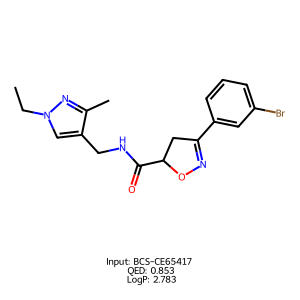

In [8]:
input_mol = Chem.MolFromSmiles(m1)
input_qed = QED.qed(input_mol)
input_logp = Crippen.MolLogP(input_mol)
Draw.MolToImage(input_mol, legend=str(f"Input: {m1_name} \n QED: " + "%.3f" % input_qed + f" \n LogP: " + "%.3f" % input_logp), subImgSize=(350,360))

In [9]:
m2 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1​"
m2_name = "BCS-CN20332"

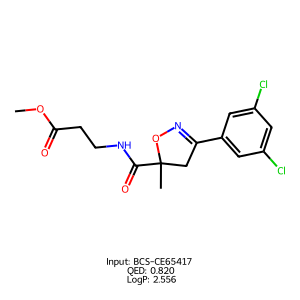

In [10]:
input_mol = Chem.MolFromSmiles(m2)
input_qed = QED.qed(input_mol)
input_logp = Crippen.MolLogP(input_mol)
Draw.MolToImage(input_mol, legend=str(f"Input: {m1_name} \n QED: " + "%.3f" % input_qed + f" \n LogP: " + "%.3f" % input_logp), subImgSize=(350,360))

### Generation #1

In [26]:
# Inferencsing using MolMIM for compound generation
molmim_response = requests.post(
    f'{MOLMIM_HOST}/generate',
    json={
        'smi': m1,
        'num_molecules': 100, #max 100
        'algorithm': 'CMA-ES',
        'property_name': 'QED', # QED or plogP
        'minimize': False,
        'min_similarity': 0.25, # Ignored if algorithm is not "CMA-ES". #max 0.7
        'iterations': 20,
        'particles': 100,
    }).json()

In [25]:
molmim_response

{'detail': [{'type': 'less_than_equal',
   'loc': ['body', 'particles'],
   'msg': 'Input should be less than or equal to 100',
   'input': 250,
   'ctx': {'le': 100}}]}

Total unique molecule designs obtained: 20


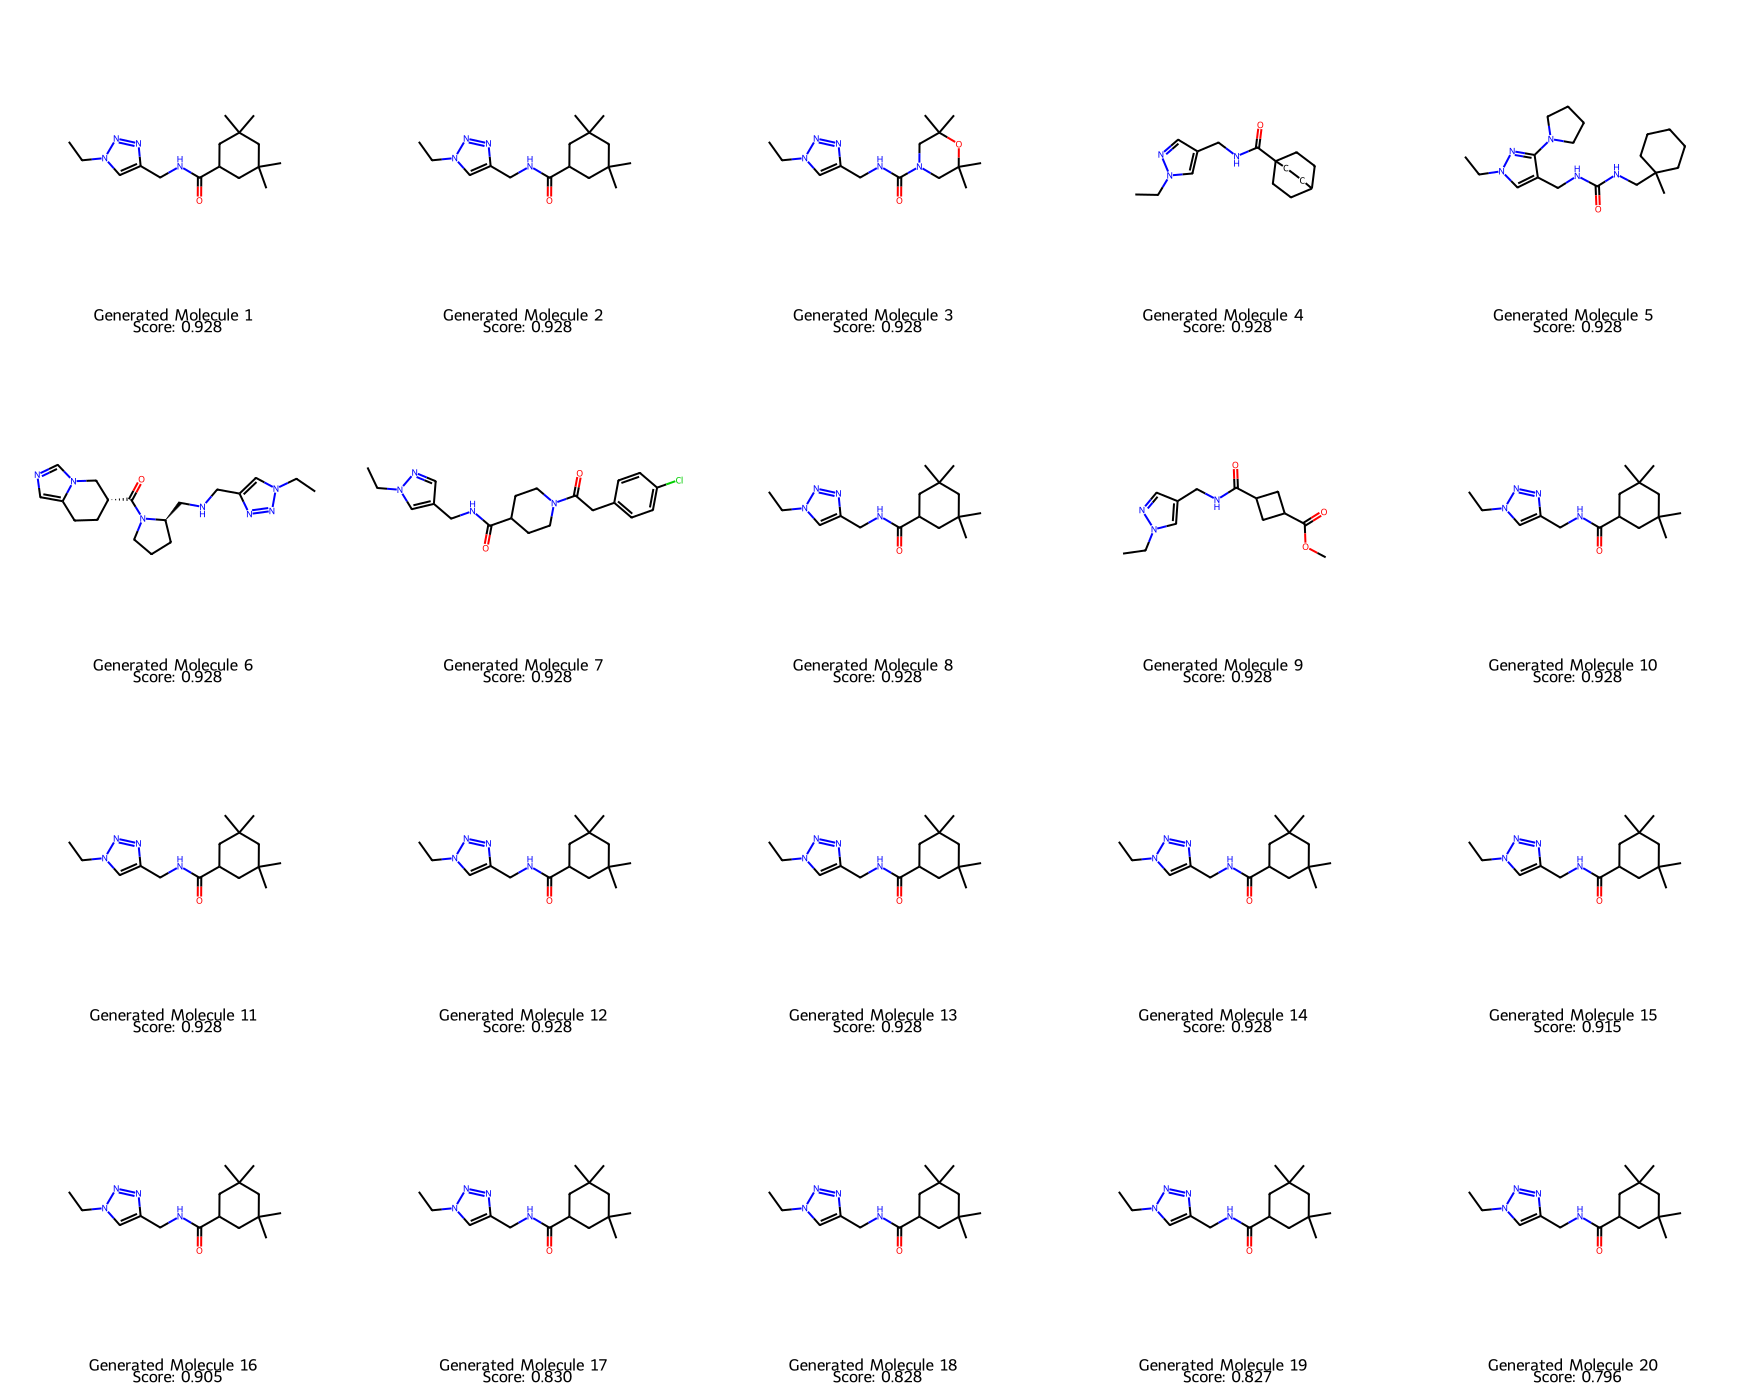

In [27]:
helper.visualize_molecules(molmim_response)

### Generation #2

In [28]:
# Inferencsing using MolMIM for compound generation
molmim_response2 = requests.post(
    f'{MOLMIM_HOST}/generate',
    json={
        'smi': m2,
        'num_molecules': 100,
        'algorithm': 'CMA-ES',
        'property_name': 'QED', # QED or plogP
        'minimize': False,
        'min_similarity': 0.25, # Ignored if algorithm is not "CMA-ES". #max 0.7
        'iterations': 20,
        'particles': 100,
    }).json()

In [ ]:
molmim_response2

Total unique molecule designs obtained: 20


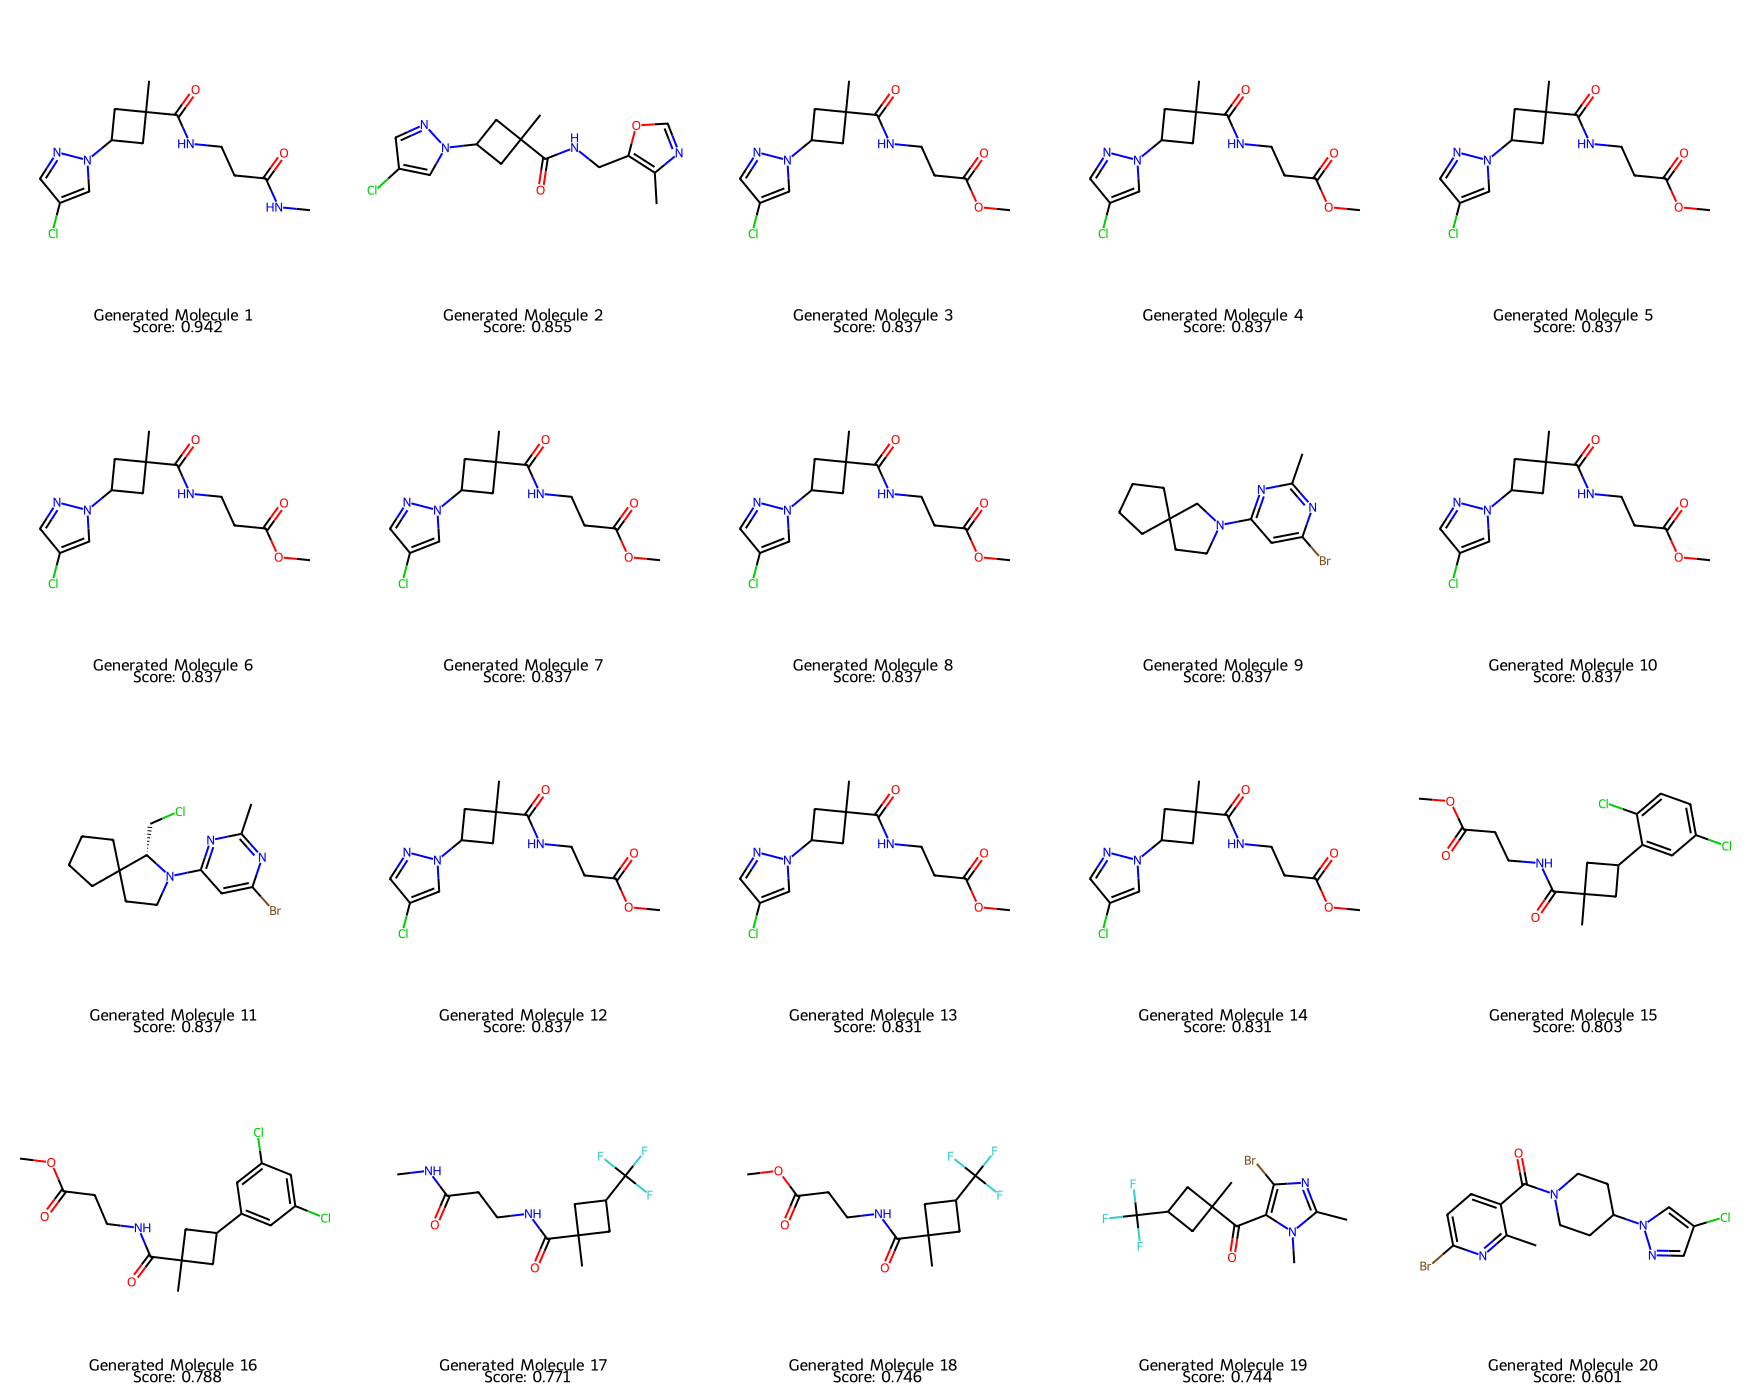

In [29]:
helper.visualize_molecules(molmim_response2)

# export

In [30]:
df1 = helper.df_from_molmim_response(molmim_response)
df2 = helper.df_from_molmim_response(molmim_response2)

In [31]:
#result_df = pd.concat([df1, df2], ignore_index=True)

#if result_df already exists
result_df = pd.concat([result_df, df1, df2], ignore_index=True)

In [32]:
result_df['LogP'] = result_df['smiles'].apply(helper.calculate_logp)
result_df['QED'] = result_df['smiles'].apply(helper.calculate_qed)

In [34]:
result_df.head(3)

,smiles,score,LogP,QED
0,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266
1,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266
2,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266


In [35]:
result_df.shape

(80, 4)

In [36]:
#result_df.to_csv('../../data/interim/molmim/unguided/XXX.csv', index=False, sep=';', header=True)